<a href="https://colab.research.google.com/github/MahdiTheGreat/Structured-machine-learning/blob/main/project%201/Structured_ML_Project_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Usage of AI

AI was mainly used to formalize my own arguments and also to generate latex formulas. I also used AI for research and to brush up on some previously learned topics e.g. axioms of Inner product.

In [ ]:
!pip install torch
!pip install torch_geometric
!pip install rdkit
!pip install torcheval
!pip install matplotlib
!git clone https://github.com/olsson-group/sml_project1.git

In [2]:
from sml_project1 import metrics, data
from sml_project1.data import ScaffoldSplitter
import torch
import torch_geometric as geom
from torch_geometric.datasets import MoleculeNet
from torch_geometric.data import Data
import matplotlib.pyplot as plt
import random
import numpy as np
import wandb
import time


# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
print(f'Using device: {device}')

Using device: cpu


In [3]:
# Filter out graphs with fewer than 2 nodes
def filter_small_graphs(dataset):
    """Remove molecules with fewer than 2 nodes (atoms) and return a new dataset."""
    initial_len = len(dataset)
    # filtered_data_list = [data_obj for data_obj in dataset if data_obj.x.size(0) >= 2]

    # To maintain compatibility with ScaffoldSplitter, we must return a true Dataset object
    # rather than just a list of Data objects. We do this by extracting the valid
    # indices and using PyTorch Geometric's built-in index_select() function to create a Subset.

    valid_indices = [i for i, data_obj in enumerate(dataset) if data_obj.x.size(0) >= 2]
    filtered_dataset = dataset.index_select(valid_indices)
    print(f"Filtered {initial_len - len(filtered_dataset)} molecules with < 2 nodes")
    return filtered_dataset


# Load and filter datasets
esol_raw = MoleculeNet(root='./storage/', name='ESOL')
esol = filter_small_graphs(esol_raw)

bbbp_raw = MoleculeNet(root='./storage/', name='BBBP')
bbbp = filter_small_graphs(bbbp_raw)


# Split datasets with scaffold stratification (Train: 80%, Val: 10%, Test: 10%)
# --- EXPLANATION OF SPLITTING METHOD ---
# We use a ScaffoldSplitter rather than a random split.
# In chemistry, a "scaffold" refers to the core structural framework of a molecule.
# Scaffold splitting groups molecules by their scaffold and completely isolates
# these groups into either Train, Validation, or Test sets.
# This ensures that the Test set contains entirely novel chemical families
# that the model has never seen before. It prevents data leakage and ensures
# that we evaluate the model's true ability to generalize to new drugs,
# rather than just memorizing structures it saw during training.
# ---------------------------------------
seed = 42
torch.manual_seed(seed)
splitter = ScaffoldSplitter()

esol_smiles = [d.smiles for d in esol]
esol_train_idx, esol_val_idx, esol_test_idx = splitter.train_valid_test_split(esol, esol_smiles, frac_train=0.8, frac_valid=0.1, frac_test=0.1, seed=seed)
esol_train_dataset = torch.utils.data.Subset(esol, esol_train_idx)
esol_val_dataset = torch.utils.data.Subset(esol, esol_val_idx)
esol_test_dataset = torch.utils.data.Subset(esol, esol_test_idx)

bbbp_smiles = [d.smiles for d in bbbp]
bbbp_train_idx, bbbp_val_idx, bbbp_test_idx = splitter.train_valid_test_split(bbbp, bbbp_smiles, frac_train=0.8, frac_valid=0.1, frac_test=0.1, seed=seed)
bbbp_train_dataset = torch.utils.data.Subset(bbbp, bbbp_train_idx)
bbbp_val_dataset = torch.utils.data.Subset(bbbp, bbbp_val_idx)
bbbp_test_dataset = torch.utils.data.Subset(bbbp, bbbp_test_idx)

print(f"ESOL: {len(esol)} molecules")
print(f"  Train: {len(esol_train_dataset)}, Val: {len(esol_val_dataset)}, Test: {len(esol_test_dataset)}")
print(f"BBBP: {len(bbbp)} molecules")
print(f"  Train: {len(bbbp_train_dataset)}, Val: {len(bbbp_val_dataset)}, Test: {len(bbbp_test_dataset)}")

def print_data_info(dataset, name, visualize=False):
    print("\n" + "="*50)
    print(f"Dataset: {name}")
    print("="*50)
    print(f"Number of graphs: {len(dataset)}")
    print(f"Number of node features: {dataset.num_node_features}")
    print(f"Number of edge features: {dataset.num_edge_features}")

    if len(dataset) > 0:
        graph = dataset[0]
        print(f"Example Graph 0: {graph}")
        print(f"Example Node Features (x): \n{graph.x[:5]} ... (truncated)")
        print(f"Example Target (y): {graph.y}")

        if visualize:
            from torch_geometric.utils import to_networkx
            import networkx as nx
            import matplotlib.pyplot as plt

            print(f"Visualizing Graph 0 from {name}...")
            G = to_networkx(graph, to_undirected=True)
            nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray')
            plt.show()
    print("="*50 + "\n")

print_data_info(esol, "ESOL", visualize=False)
print_data_info(bbbp, "BBBP", visualize=False)

Processing...
Done!


Filtered 1 molecules with < 2 nodes


Processing...
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'O=N([O-])C1=C(CN=C1NCCSCc2ncccc2)Cc3ccccc3' since it resulted in zero atoms
  self.process()
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'c1(nc(NC(N)=[NH2])sc1)CSCCNC(=[NH]C#N)NC' since it resulted in zero atoms
  self.process()
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'Cc1nc(sc1)\[NH]=C(\N)N' since it resulted in zero atoms
  self.process()
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 's1cc(CSCCN\C(NC)=[NH]\C#N)nc1\[NH]=C(\N)N' since it resulted in zero atoms
  self.process()
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'c1c(c(ncc1)CSCCN\C(=[NH]\C#N)NCC)Br' since it resulted in zero atoms
  self.process()
/usr/l

Filtered 0 molecules with < 2 nodes
ESOL: 1127 molecules
  Train: 903, Val: 112, Test: 112
BBBP: 2039 molecules
  Train: 1633, Val: 203, Test: 203

Dataset: ESOL
Number of graphs: 1127
Number of node features: 9
Number of edge features: 3
Example Graph 0: Data(x=[32, 9], edge_index=[2, 68], edge_attr=[68, 3], smiles='OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O ', y=[1, 1])
Example Node Features (x): 
tensor([[8, 0, 2, 5, 1, 0, 4, 0, 0],
        [6, 0, 4, 5, 2, 0, 4, 0, 0],
        [6, 0, 4, 5, 1, 0, 4, 0, 1],
        [8, 0, 2, 5, 0, 0, 4, 0, 1],
        [6, 0, 4, 5, 1, 0, 4, 0, 1]]) ... (truncated)
Example Target (y): tensor([[-0.7700]])


Dataset: BBBP
Number of graphs: 2039
Number of node features: 9
Number of edge features: 3
Example Graph 0: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])
Example Node Features (x): 
tensor([[17,  0,  0,  5,  0,  1,  4,  0,  0],
        [ 6,  0,  4,  5,  3,  0,  4,  0,  0],
      

In [11]:
from torch_geometric.nn import GraphConv, GATConv, global_mean_pool
import torch.nn as nn

class MolecularGraphNet(torch.nn.Module):
  # This is the parent class for both the regression and classification task

  def __init__(self, embedding, net, onehot_sizes, name="MolecularGraphNet"):
    super().__init__()
    self.embedding = embedding
    self.onehot_sizes = onehot_sizes  # List of num_classes for features 1-8
    self.net = net
    self.name = name
    self.setup_optimizer()

  def training_step(self, loss):
    loss.backward()
    self.optimizer.step()
    self.optimizer.zero_grad()

  def setup_optimizer(self):
    self.optimizer = torch.optim.Adam(self.parameters(), lr=0.001)

  def forward(self, batch):

    # Implement in children
    # We Setup the forward pass of the model for a classification task
    # this includes embedding the input data, applying the graph network,
    # pooling the results, and predicting an output.
    # where batch.x denotes the node features,
    # batch.batch denotes which graph each node belongs to

    #x = batch.x.to(torch.float32)  # prevent a type mismatch
    #print('batch is ', batch)
    x=batch.x
    atomic_embedded = self.embedding(x[:, 0])  # [num_nodes, 32]
    # Features 1-8: One-hot encode
    onehot_features = []
    for i, num_classes in enumerate(self.onehot_sizes, start=1):
     #print(f"Feature index: {i}, num_classes: {num_classes}")
     #print(f"Values for feature {i}: {x[:, i]}")
     # Add 1 to num_classes because values are 0-indexed and can go up to num_classes - 1
     # We cannot cast `batch.x` to float32 early because it contains discrete
     # categorical integers (like atomic numbers). Both `nn.Embedding` and
     # `nn.functional.one_hot` strictly require integer indices. We cast the
     # features to float32 *after* encoding them (see line 190).

     onehot = nn.functional.one_hot(x[:, i], num_classes=num_classes + 1).float()
     onehot_features.append(onehot)

    # Concatenate: embedded atomic number + all one-hot features
    x = torch.cat([atomic_embedded] + onehot_features, dim=1)

    #print("x shape after embedding is ",x.shape)

    # Apply GNN layers
    x = self.net(x, batch.edge_index, batch.batch)
    # Pool graph-level representation
    #print("net out shape: ",x.shape)
    x = geom.nn.global_mean_pool(x, batch.batch)
    return x.squeeze()

  def loss(self, y, y_hat):
    # Implement in children
    raise NotImplementedError

  def evaluate(self, y, y_hat):
    # Implement in children
    raise NotImplementedError


from torch_geometric.nn import GraphConv, GATConv, global_mean_pool
import torch.nn as nn

class MolecularGraphClassification(MolecularGraphNet):
  def __init__(self, embedding, net,onehot_sizes, name="MolecularGraphClassification"):
    super().__init__(embedding, net,onehot_sizes, name=name)
    self.sigmoid = nn.Sigmoid()
    self.bce_loss = nn.BCELoss()

  def forward(self, batch):
   return self.sigmoid(super().forward(batch))

  def loss(self, y, y_hat):
    return self.bce_loss(y_hat, y.squeeze().float())

  def evaluate(self, y, y_hat):
    roc_auc = metrics.get_auc_roc(y, y_hat)
    return {"roc_auc": roc_auc}

class MolecularGraphRegression(MolecularGraphNet):
 def __init__(self, embedding, net,onehot_sizes, name="MolecularGraphRegression"):
   super().__init__(embedding, net,onehot_sizes, name=name)

 def forward(self, batch):
   return super().forward(batch)

 def loss(self, y, y_hat):
   return torch.nn.functional.mse_loss(y.squeeze(), y_hat)

 def evaluate(self, y, y_hat):
   pcc = metrics.get_pearson_corr(y, y_hat)[0]
   rmse = metrics.get_rmse(y, y_hat)
   return {"pcc": pcc, "rmse": rmse}

class DeepSet(torch.nn.Module):
    def __init__(self, in_features, hidden_features, out_features=1, num_layers=3):
        super().__init__()
        self.num_layers = num_layers
        self.layers = nn.ModuleList()

        # Input layer
        self.layers.append(nn.Linear(in_features, hidden_features))
        self.layers.append(nn.ReLU())

        # Hidden layers
        for _ in range(num_layers - 2):
            self.layers.append(nn.Linear(hidden_features, hidden_features))
            self.layers.append(nn.ReLU())

        # Output layer
        self.layers.append(nn.Linear(hidden_features, out_features))


    def forward(self, x, edge_index, batch):
        out = x
        for layer in self.layers:
            if isinstance(layer, nn.Linear):
              out = layer(out)
            else: # Assuming ReLU
              out = layer(out)
        return out

from torch_geometric.nn import GCNConv, global_mean_pool
import torch.nn as nn

class GCN(torch.nn.Module):
# We use 1 Message Passing Layer (the GCNConv layer) followed by a ReLU activation, and then a final Linear layer to make the prediction.
# While this might sound "shallow", shallow networks are actually a massive advantage for GCNs.
# GCNs suffer heavily from a well-documented mathematical flaw called "Oversmoothing".
# If you use too many GCN layers (e.g., 3 or 4+), the features of every atom in the molecule become averaged out and mathematically identical,
# destroying the model's predictive power. shallow prevents oversmoothing while still leveraging the layer-wise propagation rule from Kipf & Welling.
    def __init__(self,in_features, hidden_features, out_features=1, num_layers=3):
        super().__init__()
        self.num_layers = num_layers
        self.layers = nn.ModuleList()

        # Input layer
        self.layers.append(GCNConv(in_features, hidden_features))

        # Hidden layers
        for _ in range(num_layers - 2):
            self.layers.append(GCNConv(hidden_features, hidden_features))

        # Output layer
        self.layers.append(nn.Linear(hidden_features, out_features))

    def forward(self, x, edge_index, batch):
        # Apply GCN layers with ReLU
        for layer in self.layers[:-1]:
            x = layer(x, edge_index)
            x = torch.relu(x)

        # Apply final linear layer
        x = self.layers[-1](x)
        return x


class GAT(torch.nn.Module):
# We use 3 Message Passing Layers to fairly compare against GCN and DeepSet.
# To maintain a matching parameter count, we use single-head attention (heads=1).
# The layers use ELU activations (as proposed in the foundational GAT paper), except the final GAT layer which uses ReLU.


    def __init__(self, in_features, hidden_features, out_features=1, num_layers=3, heads=1, concat=True):
        super().__init__()
        self.num_layers = num_layers
        self.heads = heads # Number of attention heads for the first layer
        self.layers = nn.ModuleList()

        # First GAT layer (with multiple heads)

        # Note: concat=False is used as a safety measure. Since heads=1, concatenating or averaging
        # is mathematically identical. If heads > 1 is ever used, False prevents the output dimension
        # from exploding and crashing the downstream Linear layer.

        self.layers.append(GATConv(in_features, hidden_features, heads=self.heads, concat=concat))
        self.layers.append(nn.ELU()) # Activation after first GAT layer

        # Hidden GAT layers (collapsing heads if needed, or keeping multi-head)
        # For simplicity here, let's add more multi-head GAT layers if num_layers > 2
        # A more complex implementation might alternate between multi-head and single-head
        for _ in range(num_layers - 2):
             self.layers.append(GATConv(hidden_features, hidden_features, heads=self.heads, concat=concat))
             self.layers.append(nn.ELU())


        # Final layer (either GAT or Linear). Let's use a final GAT layer that collapses heads
        # self.layers.append(GATConv(hidden_features * self.heads, hidden_features, heads=1, concat=False))
        # self.layers.append(nn.ReLU()) # Activation after final GAT layer


        # Final linear layer for prediction
        self.layers.append(nn.Linear(hidden_features, out_features))


    def forward(self, x, edge_index, batch):
        out = x
        # Apply GAT and activation layers
        for layer in self.layers[:-1]: # Apply all layers except the final linear layer
             if isinstance(layer, GATConv):
                out = layer(out, edge_index)
             else: # Activation layer
                out = layer(out)

        # Apply final linear layer
        out = self.layers[-1](out)
        return out

def plot_results(results, model_name):
    epochs = range(1, len(results['train_loss']) + 1)
    metrics_to_plot = list(results['train_metrics'][0].keys())
    num_metrics = len(metrics_to_plot)
    fig, axes = plt.subplots(1, num_metrics + 1, figsize=(6 * (num_metrics + 1), 5))

    # Plot Loss
    axes[0].plot(epochs, results['train_loss'], label='Train Loss')
    axes[0].plot(epochs, results['val_loss'], label='Validation Loss')
    axes[0].set_title(f'{model_name} - Loss over Epochs')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)

    # Plot Metrics
    for i, metric_name in enumerate(metrics_to_plot):
        train_metric_values = [m[metric_name] for m in results['train_metrics']]
        val_metric_values = [m[metric_name] for m in results['val_metrics']]
        axes[i+1].plot(epochs, train_metric_values, label=f'Train {metric_name.upper()}')
        axes[i+1].plot(epochs, val_metric_values, label=f'Validation {metric_name.upper()}')
        axes[i+1].set_title(f'{model_name} - {metric_name.upper()} over Epochs')
        axes[i+1].set_xlabel('Epoch')
        axes[i+1].set_ylabel(metric_name.upper())
        axes[i+1].legend()
        axes[i+1].grid(True)


    plt.tight_layout()
    plt.show()

def train(model, train_dataset, batch_size, val_dataset, test_dataset, n_epochs, val_factor=2, use_wandb=False, patience=15):
    import copy
    print(f"Training {model.name} with {batch_size} batch size for {n_epochs} epochs (Early Stopping Patience: {patience})...")

    if use_wandb:
     # Generate a dynamic project name
     name = f"{model.name}_epochs{n_epochs}_batch{batch_size}_layers{model.net.num_layers}"
     # Initialize a wandb run
     wandb.init(project=model.name, name=name)

    train_dataloader = geom.loader.DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True
    )

    val_dataloader = geom.loader.DataLoader(
        val_dataset, batch_size=batch_size*val_factor, drop_last=False # Fixed ZeroDivisionError
    )

    train_losses = []
    val_losses = []
    train_metrics = []
    val_metrics = []

    best_val_loss = float('inf')
    best_model_weights = None
    patience_counter = 0

    for epoch in range(n_epochs):
        # === TRAINING ===
        model.train()
        epoch_train_loss = 0
        all_train_y = []
        all_train_y_hat = []

        for i, batch in enumerate(train_dataloader):
            batch = batch.to(device)

            # Forward pass
            y_hat = model(batch)

            if epoch == 0 and i == 0:
                print(f"\nArchitecture of {model.name} after first forward pass:")
                print(model)
                total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
                print(f"Total Trainable Parameters: {total_params:,}\n")

            # Calculate loss
            loss = model.loss(batch.y, y_hat)

            # Backward pass
            model.training_step(loss)

            epoch_train_loss += loss.item()

            # Safely move predictions to CPU RAM to prevent GPU Out-of-Memory leaks
            # (sklearn metrics require CPU anyway). .view(-1) flattens the tensor
            # to prevent torch.cat crashes if a batch only has 1 molecule left.
            all_train_y.append(batch.y.cpu().view(-1))
            all_train_y_hat.append(y_hat.detach().cpu().view(-1))

        # Calculate epoch train metrics properly
        all_train_y = torch.cat(all_train_y, dim=0)
        all_train_y_hat = torch.cat(all_train_y_hat, dim=0)
        try:
            avg_train_metrics = model.evaluate(all_train_y, all_train_y_hat)
        except Exception:
            avg_train_metrics = {"error": 0.0}

        # === VALIDATION ===
        model.eval()
        epoch_val_loss = 0
        all_val_y = []
        all_val_y_hat = []

        with torch.no_grad():
            for val_batch in val_dataloader:
                val_batch = val_batch.to(device)

                # Forward pass
                y_hat = model(val_batch)

                # Calculate loss
                loss = model.loss(val_batch.y, y_hat)
                epoch_val_loss += loss.item()

                # Offload to CPU to prevent memory leaks and flatten to 1D
                all_val_y.append(val_batch.y.cpu().view(-1))
                all_val_y_hat.append(y_hat.cpu().view(-1))

        # Calculate epoch val metrics properly
        all_val_y = torch.cat(all_val_y, dim=0)
        all_val_y_hat = torch.cat(all_val_y_hat, dim=0)
        try:
            avg_val_metrics = model.evaluate(all_val_y, all_val_y_hat)
        except Exception:
            avg_val_metrics = {"error": 0.0}

        # Average metrics
        avg_train_loss = epoch_train_loss / max(1, len(train_dataloader))
        avg_val_loss = epoch_val_loss / max(1, len(val_dataloader))


        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        train_metrics.append(avg_train_metrics)
        val_metrics.append(avg_val_metrics)
        if (epoch + 1) % 5 == 0:
         print(f"Epoch {epoch+1}/{n_epochs}")
         print(f"  Train - Loss: {avg_train_loss:.4f}, {', '.join([f'{k}: {v:.4f}' for k, v in avg_train_metrics.items()])}")
         print(f"  Val   - Loss: {avg_val_loss:.4f}, {', '.join([f'{k}: {v:.4f}' for k, v in avg_val_metrics.items()])}")

        if use_wandb:
         # Log metrics to wandb
         wandb.log({
             "epoch": epoch + 1,
             "train_loss": avg_train_loss,
             "val_loss": avg_val_loss,
             **{f"train_{k}": v for k, v in avg_train_metrics.items()},
             **{f"val_{k}": v for k, v in avg_val_metrics.items()}
         })

        # Early Stopping Logic
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch+1}!")
            break

    # Restore the best model weights before testing
    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)

    # === TEST EVALUATION ===
    test_dataloader = geom.loader.DataLoader(test_dataset, batch_size=batch_size*val_factor, drop_last=False)
    model.eval()
    all_test_y = []
    all_test_y_hat = []

    with torch.no_grad():
        for test_batch in test_dataloader:
            test_batch = test_batch.to(device)
            y_hat = model(test_batch)
            # Offload to CPU to prevent memory leaks and flatten to 1D
            all_test_y.append(test_batch.y.cpu().view(-1))
            all_test_y_hat.append(y_hat.cpu().view(-1))

    all_test_y = torch.cat(all_test_y, dim=0)
    all_test_y_hat = torch.cat(all_test_y_hat, dim=0)
    final_test_metrics = model.evaluate(all_test_y, all_test_y_hat)

    print(f"  Final Test Metrics: {', '.join([f'{k}: {v:.4f}' for k, v in final_test_metrics.items()])}")


    hist= {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "train_metrics": train_metrics,
        "val_metrics": val_metrics,
        "test_metrics": final_test_metrics
    }

    plot_results(hist, model.name)

    # Finish the wandb run
    if use_wandb:
        wandb.finish()

    return hist

def get_max_values(dataset):
    # Dynamically get the number of columns (features) from the first molecule
    num_features = dataset[0].x.shape[1]

    max_vals = []
    # Loop over the actual dynamic length
    for i in range(num_features):
        max_val = int(max([data.x[:, i].max().item() for data in dataset]))
        max_vals.append(max_val)
    return max_vals


from collections import defaultdict

def reset_weights(m):
    """Recursively resets the parameters of a PyTorch module to new random values."""
    if hasattr(m, 'reset_parameters'):
        m.reset_parameters()

def run_experiment(model_class, model_kwargs, train_ds, val_ds, test_ds, batch_size, n_epochs, repeat_factor=3):
    print(f"\n{'='*50}")
    print(f"Running Experiment: {model_kwargs['name']} ({repeat_factor} replicates)")
    print(f"{'='*50}")

    all_test_metrics = defaultdict(list)
    start_time = time.time()

    # We instantiate the model architecture here...
    model = model_class(**model_kwargs).to(device)

    for i in range(repeat_factor):
        print(f"\n--- Replicate {i+1}/{repeat_factor} ---")
        # ...but we MUST force PyTorch to assign completely new random weights for each replicate!
        # Otherwise, the loop just continues training the exact same model!
        model.apply(reset_weights)

        hist = train(model, train_ds, batch_size, val_ds, test_ds, n_epochs)

        for k, v in hist['test_metrics'].items():
            all_test_metrics[k].append(v)

    end_time = time.time()
    print(f"\n>>> FINAL AGGREGATED RESULTS FOR {model_kwargs['name']} <<<")
    print(f"Total time taken: {end_time - start_time:.2f} seconds")

    final_metrics_summary = {}
    for k, v_list in all_test_metrics.items():
        mean_val = np.mean(v_list)
        std_val = np.std(v_list)
        print(f"  Test {k.upper()}: {mean_val:.4f} ± {std_val:.4f}")
        final_metrics_summary[k] = (mean_val, std_val)

    return final_metrics_summary



in features: 59

Running Experiment: DeepSet Regression (3 replicates)

--- Replicate 1/3 ---
Training DeepSet Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=59, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 9,793

Epoch 5/1000
  Train - Loss: 3.2523, pcc: 0.4251, rmse: 1.7845
  Val   - Loss: 6.9755, pcc: 0.8073, rmse: 2.5461
Epoch 10/1000
  Train - Loss: 3.0235, pcc: 0.4727, rmse: 1.7129
  Val   - Loss: 5.8768, pcc: 0.7741, rmse: 2.3404
Epoch 15/1000
  Train - Loss: 2.6026, pcc: 0.5551, rmse: 1.6184
  Val   - Loss: 4.7528, pcc: 0.7284, rmse: 2.1211
Epoch 20/1000
  Train - Loss: 2.3053

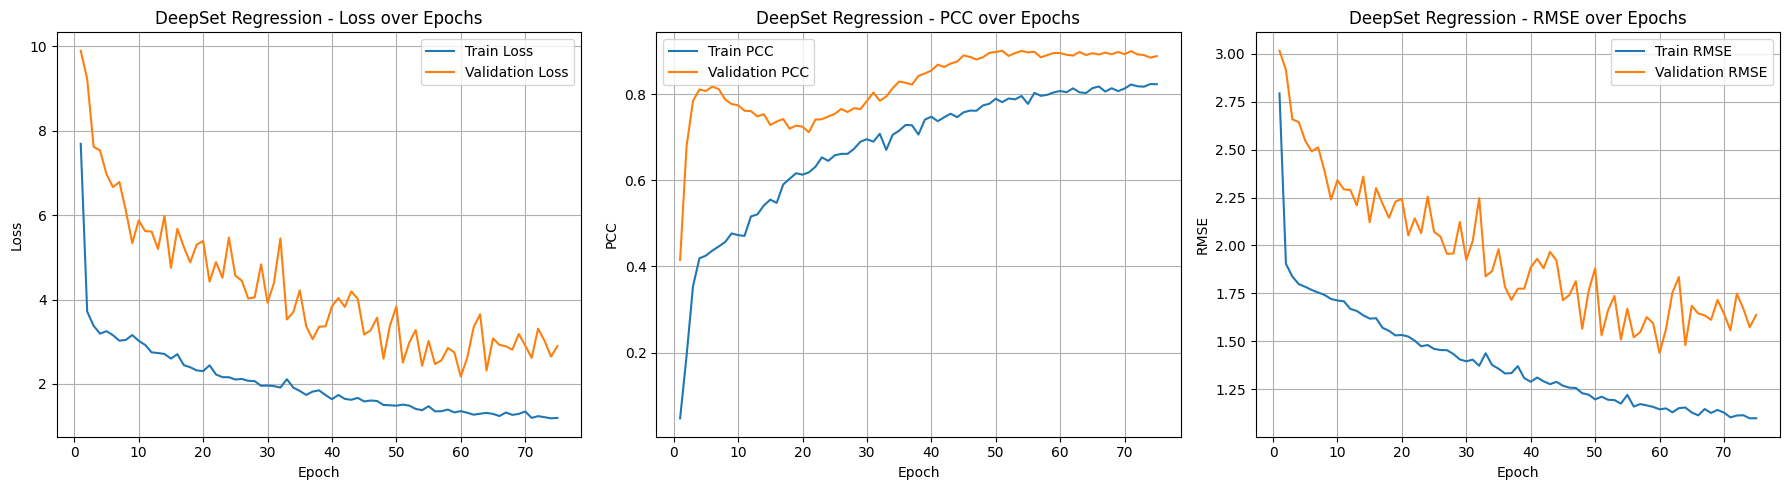


--- Replicate 2/3 ---
Training DeepSet Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=59, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 9,793

Epoch 5/1000
  Train - Loss: 3.0442, pcc: 0.4474, rmse: 1.7511
  Val   - Loss: 6.1744, pcc: 0.7832, rmse: 2.4004
Epoch 10/1000
  Train - Loss: 2.7963, pcc: 0.5148, rmse: 1.6867
  Val   - Loss: 6.1262, pcc: 0.7657, rmse: 2.3926
Epoch 15/1000
  Train - Loss: 2.7312, pcc: 0.5579, rmse: 1.6333
  Val   - Loss: 6.5131, pcc: 0.7248, rmse: 2.4628
Epoch 20/1000
  Train - Loss: 2.3573, pcc: 0.6087, rmse: 1.5457
  Val   - Loss: 5.1604, pcc: 0.7095, rmse: 

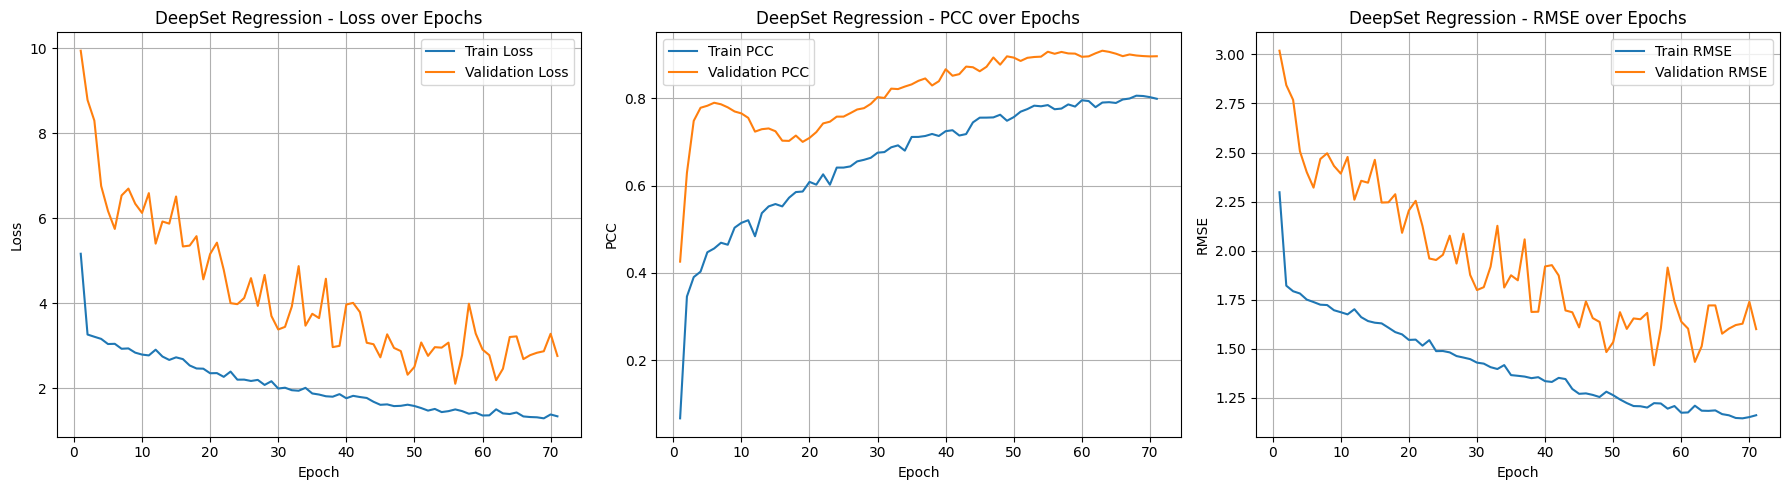


--- Replicate 3/3 ---
Training DeepSet Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=59, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 9,793

Epoch 5/1000
  Train - Loss: 3.2057, pcc: 0.4293, rmse: 1.7757
  Val   - Loss: 7.2687, pcc: 0.7178, rmse: 2.5983
Epoch 10/1000
  Train - Loss: 2.9518, pcc: 0.4923, rmse: 1.7133
  Val   - Loss: 6.7119, pcc: 0.7684, rmse: 2.4979
Epoch 15/1000
  Train - Loss: 2.6993, pcc: 0.5328, rmse: 1.6536
  Val   - Loss: 6.5196, pcc: 0.7479, rmse: 2.4615
Epoch 20/1000
  Train - Loss: 2.4974, pcc: 0.5863, rmse: 1.5761
  Val   - Loss: 5.0581, pcc: 0.6907, rmse: 

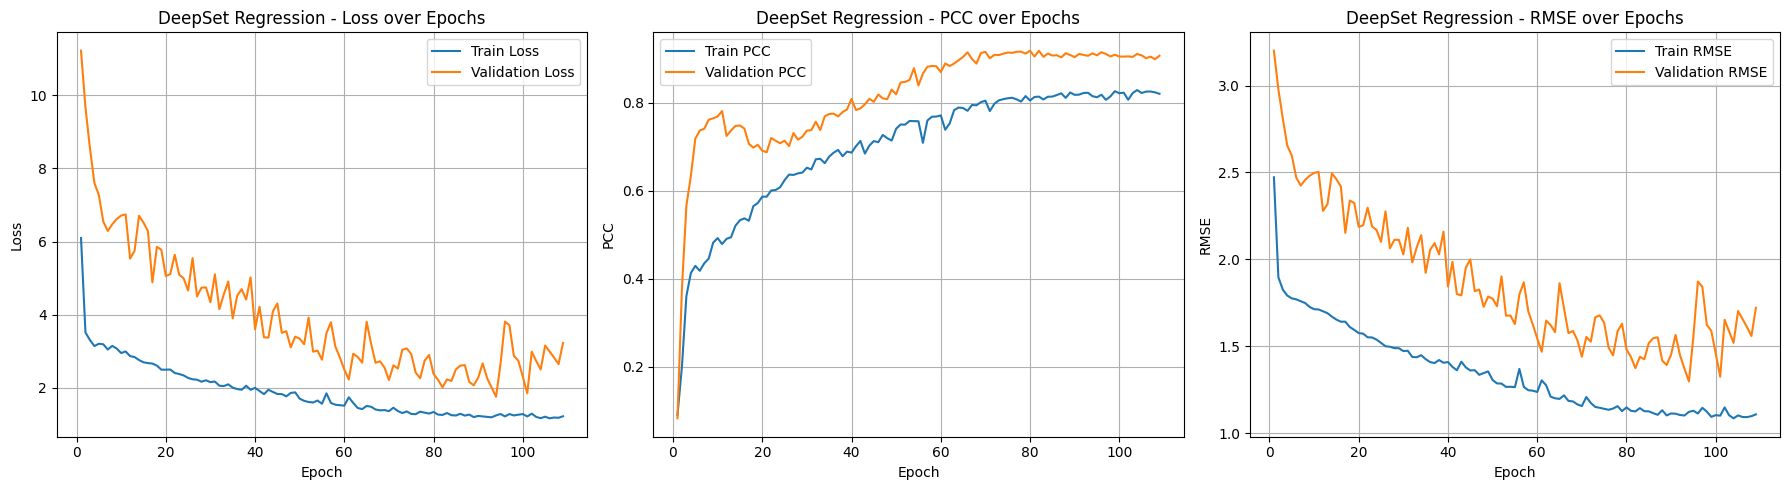


>>> FINAL AGGREGATED RESULTS FOR DeepSet Regression <<<
Total time taken: 45.23 seconds
  Test PCC: 0.7761 ± 0.0177
  Test RMSE: 1.3564 ± 0.0398


In [5]:
esol_max_vals = get_max_values(esol)


repeat_factor=3
reg_batch_size = 32
reg_n_epochs = 1000
reg_onehot_sizes=esol_max_vals[1:]

import sys
DEBUG_MODE = '--test' in sys.argv
if DEBUG_MODE:
    print("\n[WARNING] Running in FAST DEBUG MODE. Disabling large epochs and replicates.")
    reg_n_epochs = 1
    repeat_factor = 1
    # Shrink datasets
    esol_train_dataset = torch.utils.data.Subset(esol_train_dataset, range(min(10, len(esol_train_dataset))))
    esol_val_dataset = torch.utils.data.Subset(esol_val_dataset, range(min(5, len(esol_val_dataset))))
    esol_test_dataset = torch.utils.data.Subset(esol_test_dataset, range(min(5, len(esol_test_dataset))))

# Setup
hidden_features = 64
embedding_dim=32

# Total dimension: 32 (atomic) + sum of one-hot dimensions
# Add 1 to each size in esol_max_vals[1:] for one-hot encoding
# There are 9 features in the ESOL dataset
in_features = embedding_dim + sum([size + 1 for size in esol_max_vals[1:]])
print(f"in features: {in_features}")

# --- REGRESSION EXPERIMENTS (ESOL) ---

reg_results = {}
reg_results["DeepSet"] = run_experiment(MolecularGraphRegression,
               {"embedding": torch.nn.Embedding(num_embeddings=esol_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": DeepSet(in_features, hidden_features),
                "onehot_sizes": reg_onehot_sizes,
                "name": "DeepSet Regression"},
               esol_train_dataset, esol_val_dataset, esol_test_dataset, reg_batch_size, reg_n_epochs)


Running Experiment: GCN Regression (3 replicates)

--- Replicate 1/3 ---
Training GCN Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of GCN Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(59, 64)
      (1): GCNConv(64, 64)
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 9,793

Epoch 5/1000
  Train - Loss: 3.0109, pcc: 0.5065, rmse: 1.7274
  Val   - Loss: 7.1373, pcc: 0.7196, rmse: 2.5686
Epoch 10/1000
  Train - Loss: 2.5599, pcc: 0.5679, rmse: 1.6022
  Val   - Loss: 5.3540, pcc: 0.7411, rmse: 2.2352
Epoch 15/1000
  Train - Loss: 2.1624, pcc: 0.6445, rmse: 1.4843
  Val   - Loss: 4.0227, pcc: 0.7701, rmse: 1.9640
Epoch 20/1000
  Train - Loss: 2.0026, pcc: 0.6857, rmse: 1.4140
  Val   - Loss: 3.7848, pcc: 0.7977, rmse: 1.9082
Epoch 25/1000
  Train - Loss: 1.8600, pcc: 0.7166, rmse: 1.3

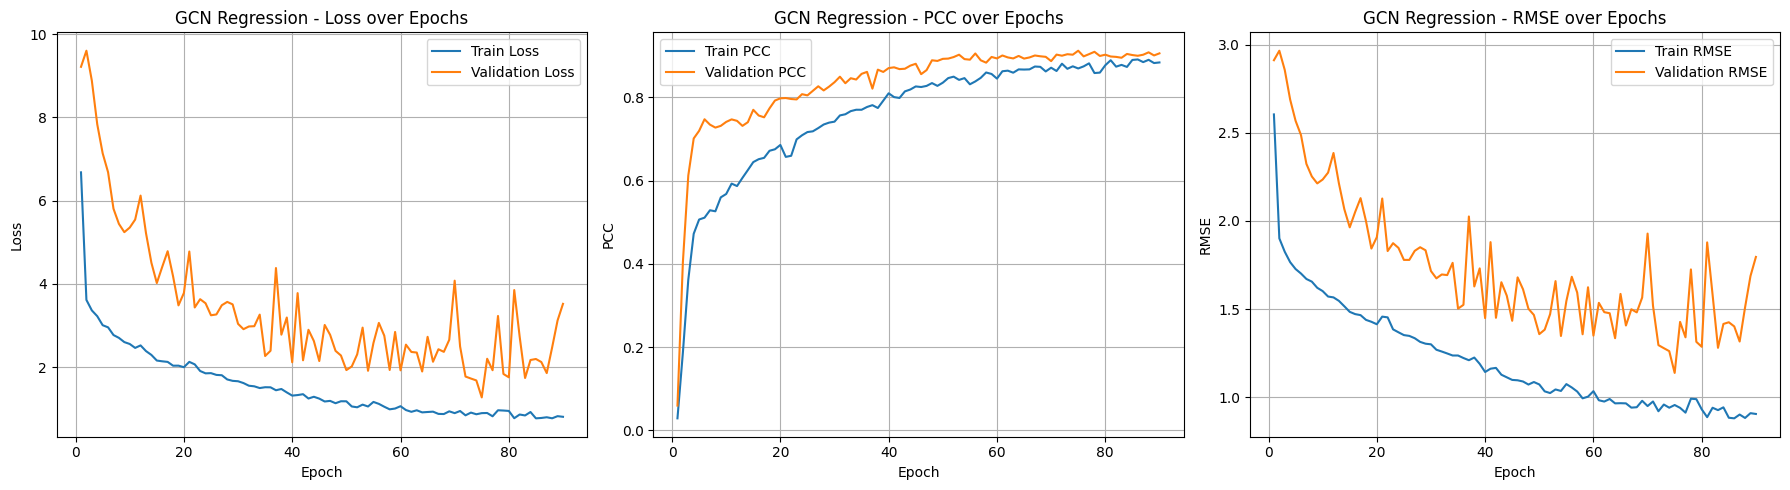


--- Replicate 2/3 ---
Training GCN Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of GCN Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(59, 64)
      (1): GCNConv(64, 64)
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 9,793

Epoch 5/1000
  Train - Loss: 2.9162, pcc: 0.4640, rmse: 1.7211
  Val   - Loss: 6.0100, pcc: 0.7555, rmse: 2.3642
Epoch 10/1000
  Train - Loss: 2.4688, pcc: 0.5903, rmse: 1.5719
  Val   - Loss: 5.7865, pcc: 0.7602, rmse: 2.3204
Epoch 15/1000
  Train - Loss: 2.0718, pcc: 0.6724, rmse: 1.4424
  Val   - Loss: 3.7839, pcc: 0.8110, rmse: 1.9008
Epoch 20/1000
  Train - Loss: 1.9131, pcc: 0.7138, rmse: 1.3580
  Val   - Loss: 3.4775, pcc: 0.8264, rmse: 1.8258
Epoch 25/1000
  Train - Loss: 1.8256, pcc: 0.7216, rmse: 1.3388
  Val   - Loss: 2.6026, pcc: 0.8518, rmse: 1.59

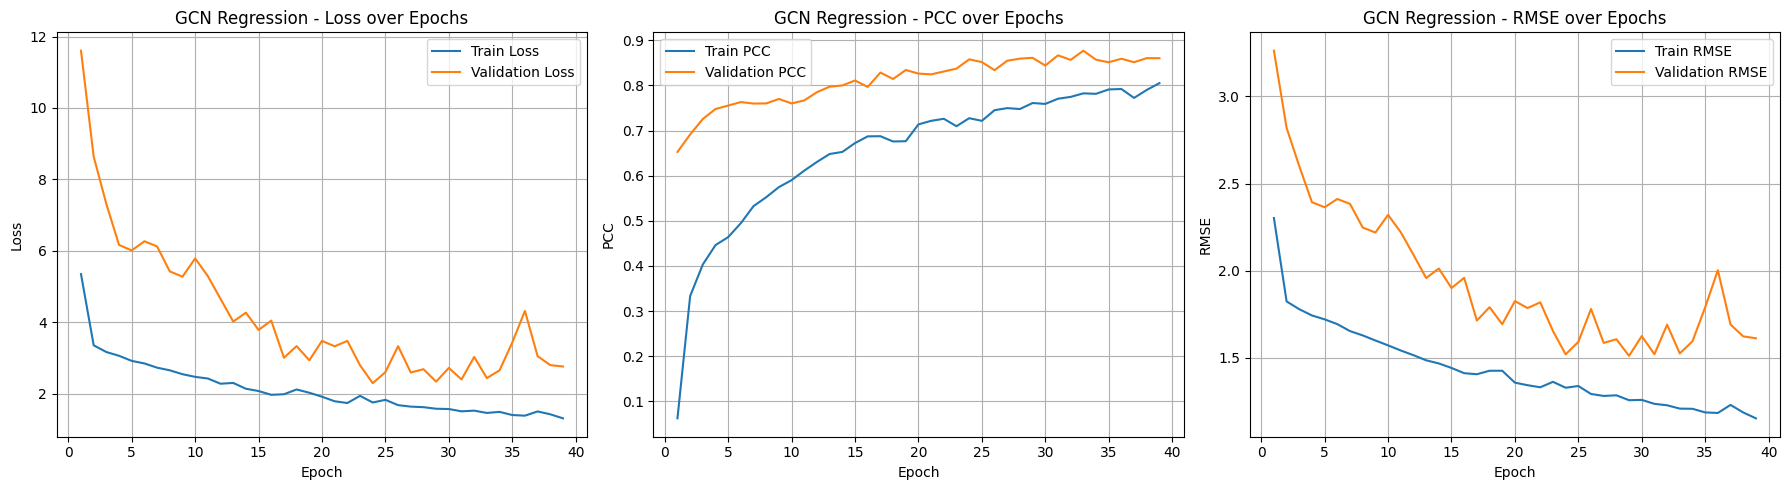


--- Replicate 3/3 ---
Training GCN Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of GCN Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(59, 64)
      (1): GCNConv(64, 64)
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 9,793

Epoch 5/1000
  Train - Loss: 3.1499, pcc: 0.4209, rmse: 1.7695
  Val   - Loss: 7.2760, pcc: 0.6354, rmse: 2.5931
Epoch 10/1000
  Train - Loss: 2.6975, pcc: 0.5366, rmse: 1.6502
  Val   - Loss: 5.8540, pcc: 0.7902, rmse: 2.3330
Epoch 15/1000
  Train - Loss: 2.2923, pcc: 0.6285, rmse: 1.5206
  Val   - Loss: 4.8350, pcc: 0.8037, rmse: 2.1294
Epoch 20/1000
  Train - Loss: 2.0152, pcc: 0.6785, rmse: 1.4292
  Val   - Loss: 3.6576, pcc: 0.7990, rmse: 1.8729
Epoch 25/1000
  Train - Loss: 1.9971, pcc: 0.6768, rmse: 1.4232
  Val   - Loss: 2.9148, pcc: 0.8220, rmse: 1.69

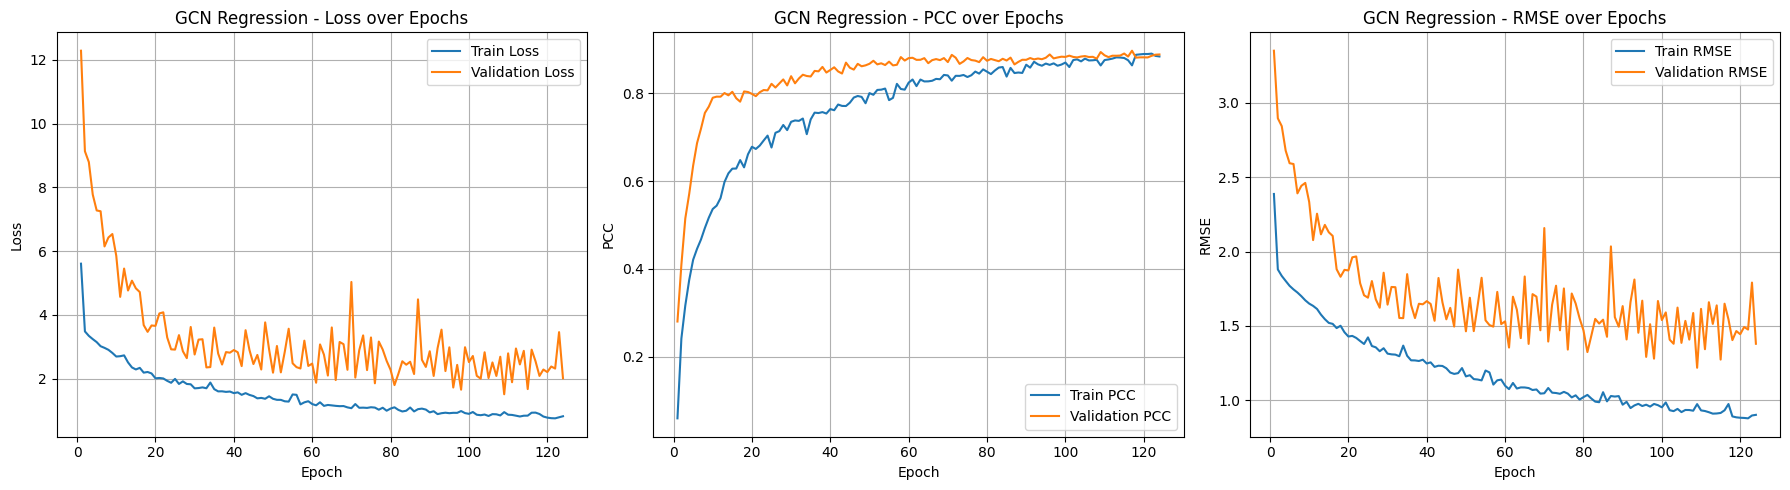


>>> FINAL AGGREGATED RESULTS FOR GCN Regression <<<
Total time taken: 58.43 seconds
  Test PCC: 0.7270 ± 0.0584
  Test RMSE: 1.5820 ± 0.0950


In [6]:
reg_results["GCN"] = run_experiment(MolecularGraphRegression,
               {"embedding": torch.nn.Embedding(num_embeddings=esol_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": GCN(in_features, hidden_features),
                "onehot_sizes": reg_onehot_sizes,
                "name": "GCN Regression"},
               esol_train_dataset, esol_val_dataset, esol_test_dataset, reg_batch_size, reg_n_epochs)


Running Experiment: GAT Regression (3 replicates)

--- Replicate 1/3 ---
Training GAT Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of GAT Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(59, 64, heads=1)
      (1): ELU(alpha=1.0)
      (2): GATConv(64, 64, heads=1)
      (3): ELU(alpha=1.0)
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 10,049

Epoch 5/1000
  Train - Loss: 2.9578, pcc: 0.4489, rmse: 1.7283
  Val   - Loss: 6.0258, pcc: 0.7853, rmse: 2.3687
Epoch 10/1000
  Train - Loss: 2.6563, pcc: 0.5417, rmse: 1.6261
  Val   - Loss: 4.4084, pcc: 0.7977, rmse: 2.0381
Epoch 15/1000
  Train - Loss: 2.3862, pcc: 0.6025, rmse: 1.5435
  Val   - Loss: 4.3558, pcc: 0.7594, rmse: 2.0380
Epoch 20/1000
  Train - Loss: 2.1202, pcc: 0.6504, rmse: 1.4683
  Val   - Loss: 4.2704, pcc: 0.7447, rm

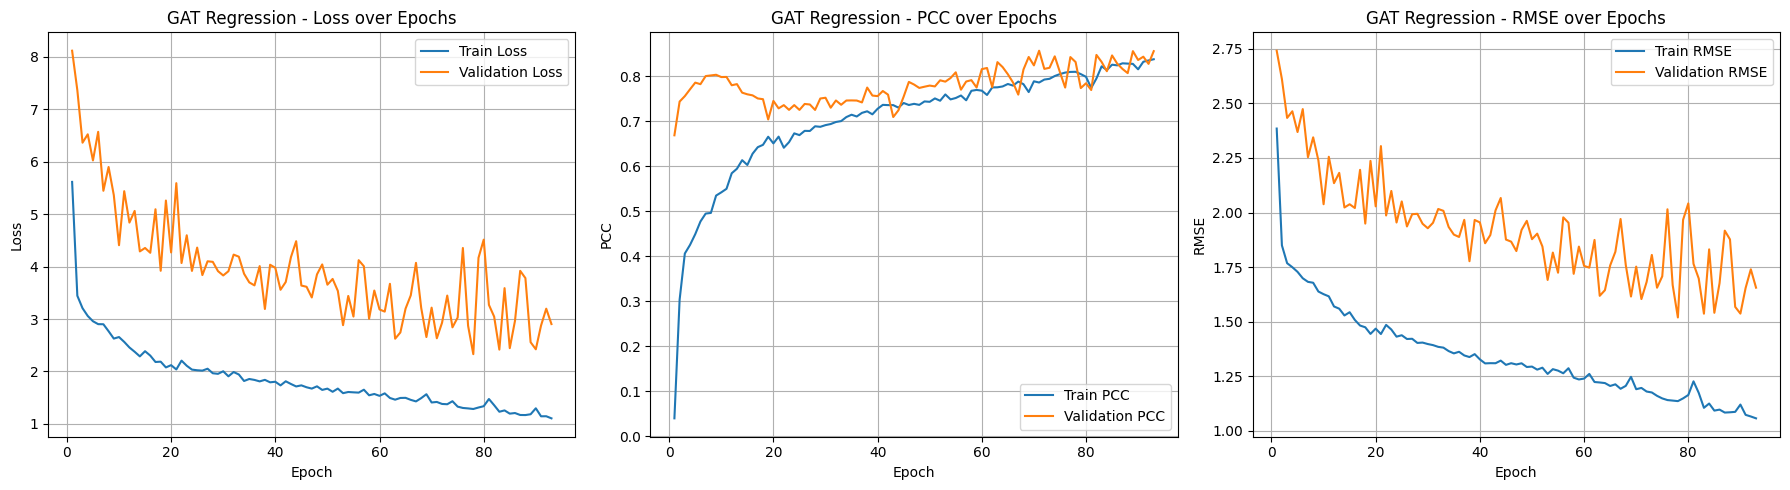


--- Replicate 2/3 ---
Training GAT Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of GAT Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(59, 64, heads=1)
      (1): ELU(alpha=1.0)
      (2): GATConv(64, 64, heads=1)
      (3): ELU(alpha=1.0)
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 10,049

Epoch 5/1000
  Train - Loss: 2.9859, pcc: 0.4770, rmse: 1.6993
  Val   - Loss: 6.0140, pcc: 0.7672, rmse: 2.3618
Epoch 10/1000
  Train - Loss: 2.5128, pcc: 0.5658, rmse: 1.5962
  Val   - Loss: 4.8767, pcc: 0.7867, rmse: 2.1365
Epoch 15/1000
  Train - Loss: 2.4674, pcc: 0.5896, rmse: 1.5614
  Val   - Loss: 4.8747, pcc: 0.7510, rmse: 2.1380
Epoch 20/1000
  Train - Loss: 2.1611, pcc: 0.6499, rmse: 1.4714
  Val   - Loss: 4.0700, pcc: 0.7466, rmse: 1.9676
Epoch 25/1000
  Train - Loss: 1.9985, pc

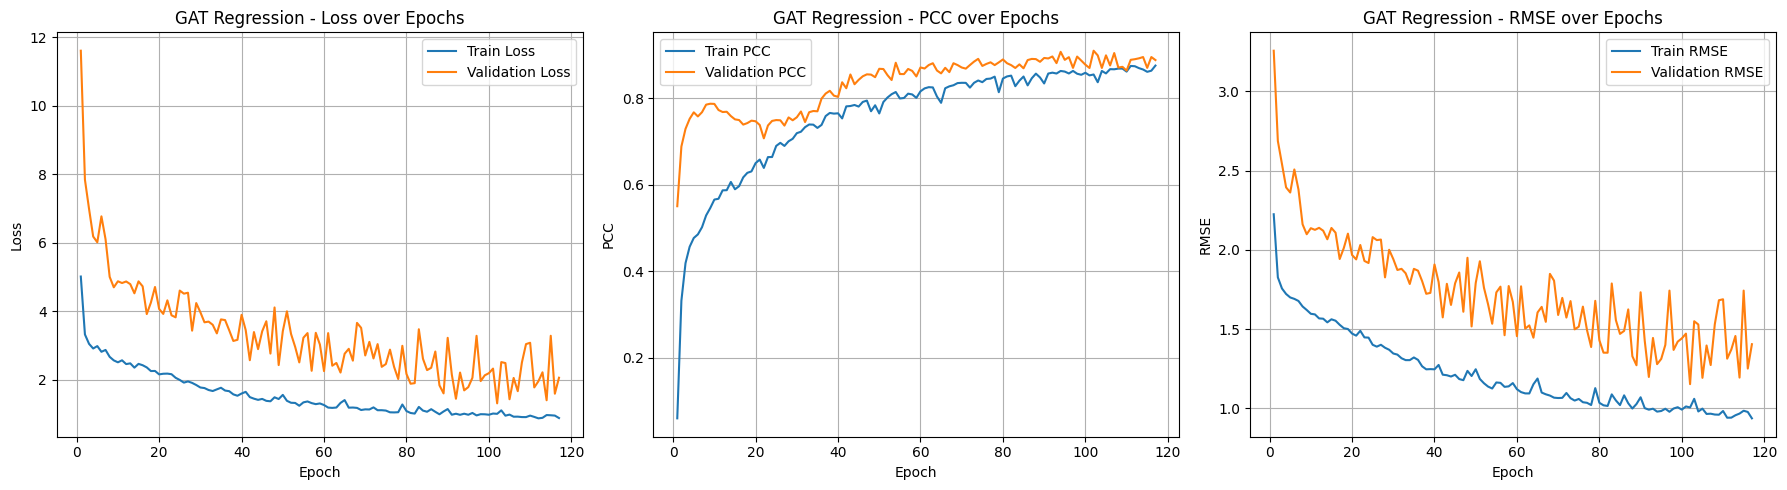


--- Replicate 3/3 ---
Training GAT Regression with 32 batch size for 1000 epochs (Early Stopping Patience: 15)...

Architecture of GAT Regression after first forward pass:
MolecularGraphRegression(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(59, 64, heads=1)
      (1): ELU(alpha=1.0)
      (2): GATConv(64, 64, heads=1)
      (3): ELU(alpha=1.0)
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Total Trainable Parameters: 10,049

Epoch 5/1000
  Train - Loss: 2.8306, pcc: 0.4853, rmse: 1.6934
  Val   - Loss: 5.9542, pcc: 0.7579, rmse: 2.3551
Epoch 10/1000
  Train - Loss: 2.5937, pcc: 0.5753, rmse: 1.5844
  Val   - Loss: 4.4886, pcc: 0.7901, rmse: 2.0548
Epoch 15/1000
  Train - Loss: 2.4109, pcc: 0.6145, rmse: 1.5252
  Val   - Loss: 5.1055, pcc: 0.7400, rmse: 2.1831
Epoch 20/1000
  Train - Loss: 2.2511, pcc: 0.6543, rmse: 1.4636
  Val   - Loss: 3.9935, pcc: 0.7675, rmse: 1.9438
Epoch 25/1000
  Train - Loss: 1.9817, pc

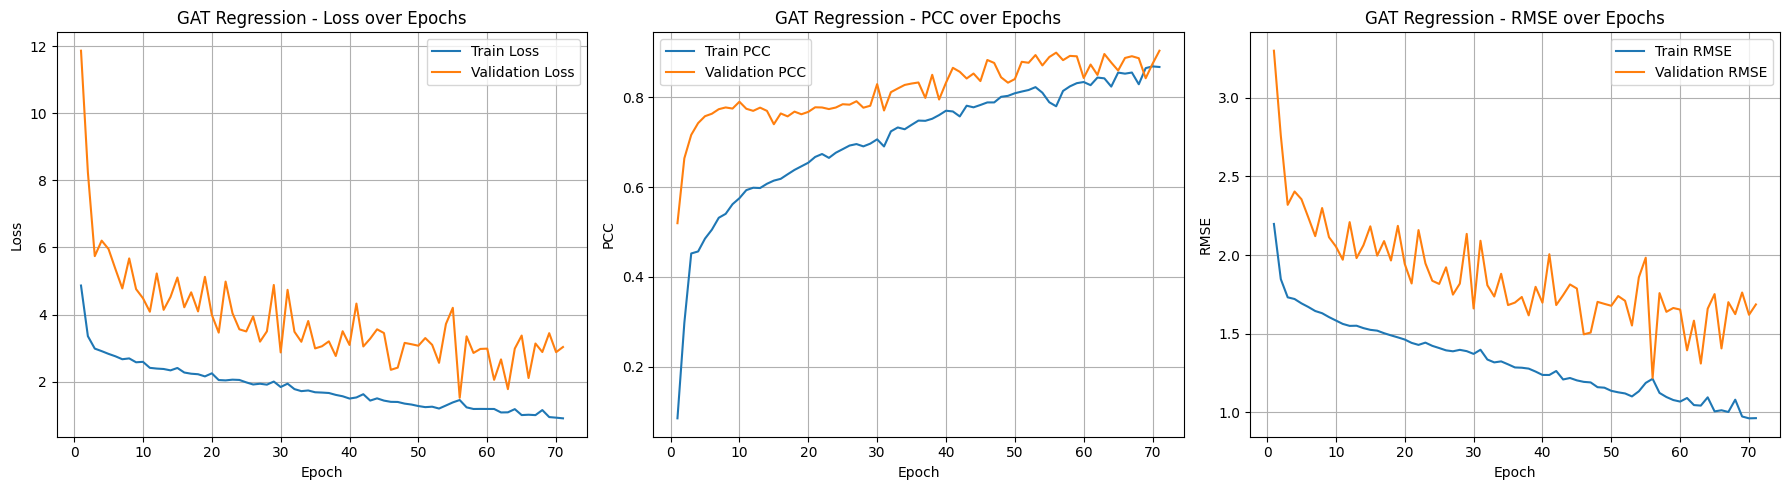


>>> FINAL AGGREGATED RESULTS FOR GAT Regression <<<
Total time taken: 87.70 seconds
  Test PCC: 0.7153 ± 0.0434
  Test RMSE: 1.4896 ± 0.0939


In [12]:
reg_results["GAT"] = run_experiment(MolecularGraphRegression,
               {"embedding": torch.nn.Embedding(num_embeddings=esol_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": GAT(in_features, hidden_features),
                "onehot_sizes": reg_onehot_sizes,
                "name": "GAT Regression"},
               esol_train_dataset, esol_val_dataset, esol_test_dataset, reg_batch_size, reg_n_epochs)


Running Experiment: DeepSet Classification (3 replicates)

--- Replicate 1/3 ---
Training DeepSet Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=63, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 10,049

Epoch 5/200
  Train - Loss: 0.4819, roc_auc: 0.7737
  Val   - Loss: 0.4074, roc_auc: 0.8523
Epoch 10/200
  Train - Loss: 0.4408, roc_auc: 0.8102
  Val   - Loss: 0.3878, roc_auc: 0.8538
Epoch 15/200
  Train - Loss: 0.4253, roc_auc: 0.8162
  Val   - Loss: 0.3526, roc_auc: 0.8682
Epoch 20/200
  Train - Loss: 0.4155, roc_auc: 0.8214

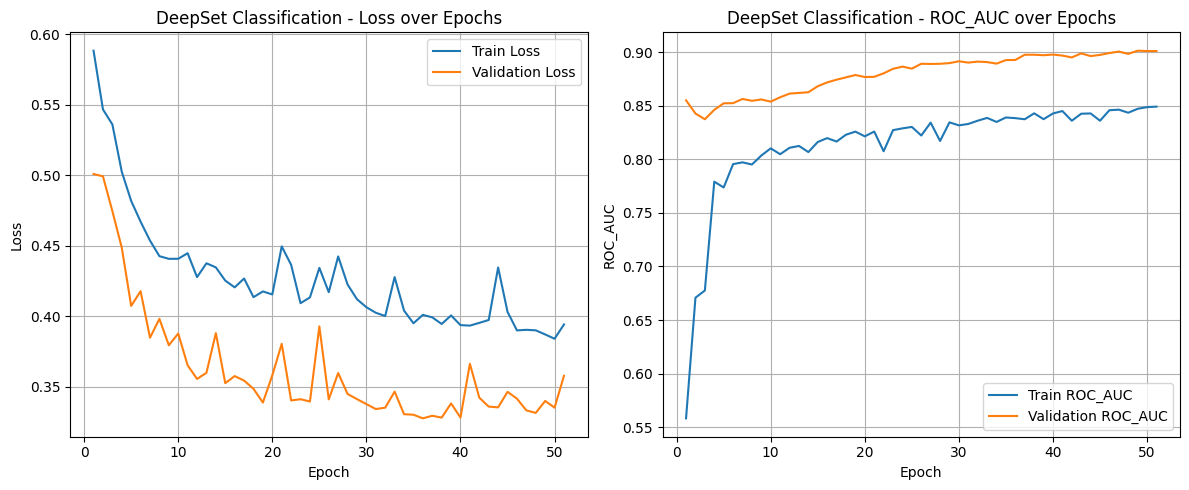


--- Replicate 2/3 ---
Training DeepSet Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=63, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 10,049

Epoch 5/200
  Train - Loss: 0.4504, roc_auc: 0.7946
  Val   - Loss: 0.3855, roc_auc: 0.8507
Epoch 10/200
  Train - Loss: 0.4305, roc_auc: 0.8111
  Val   - Loss: 0.3604, roc_auc: 0.8710
Epoch 15/200
  Train - Loss: 0.4299, roc_auc: 0.8088
  Val   - Loss: 0.3524, roc_auc: 0.8798
Epoch 20/200
  Train - Loss: 0.4099, roc_auc: 0.8274
  Val   - Loss: 0.3385, roc_auc: 0.8860
Epoch 25/200
  Tra

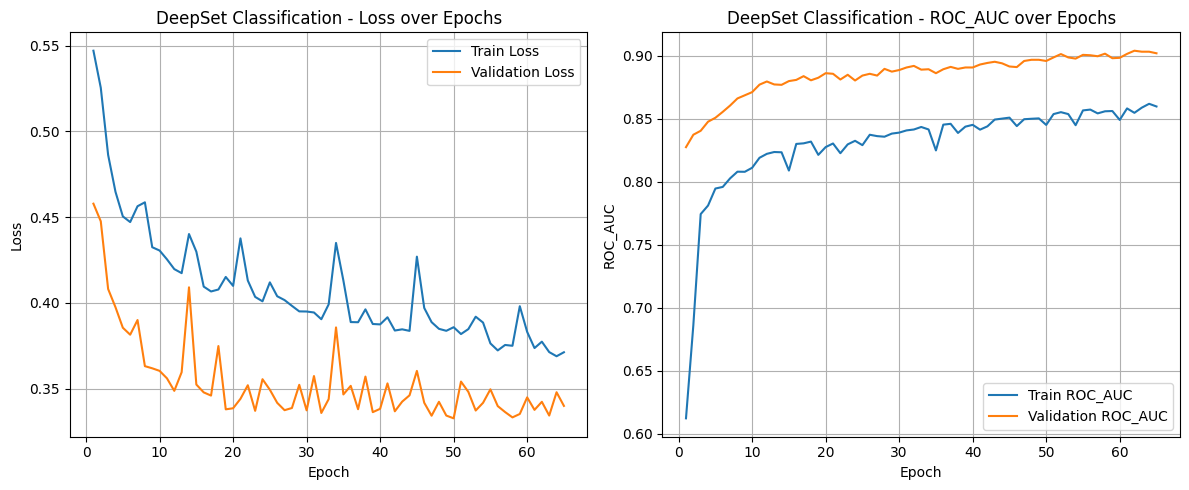


--- Replicate 3/3 ---
Training DeepSet Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of DeepSet Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): DeepSet(
    (layers): ModuleList(
      (0): Linear(in_features=63, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 10,049

Epoch 5/200
  Train - Loss: 0.4500, roc_auc: 0.8003
  Val   - Loss: 0.3828, roc_auc: 0.8527
Epoch 10/200
  Train - Loss: 0.4280, roc_auc: 0.8167
  Val   - Loss: 0.3581, roc_auc: 0.8751
Epoch 15/200
  Train - Loss: 0.4227, roc_auc: 0.8182
  Val   - Loss: 0.3568, roc_auc: 0.8815
Epoch 20/200
  Train - Loss: 0.4124, roc_auc: 0.8291
  Val   - Loss: 0.3491, roc_auc: 0.8807
Epoch 25/200
  Tra

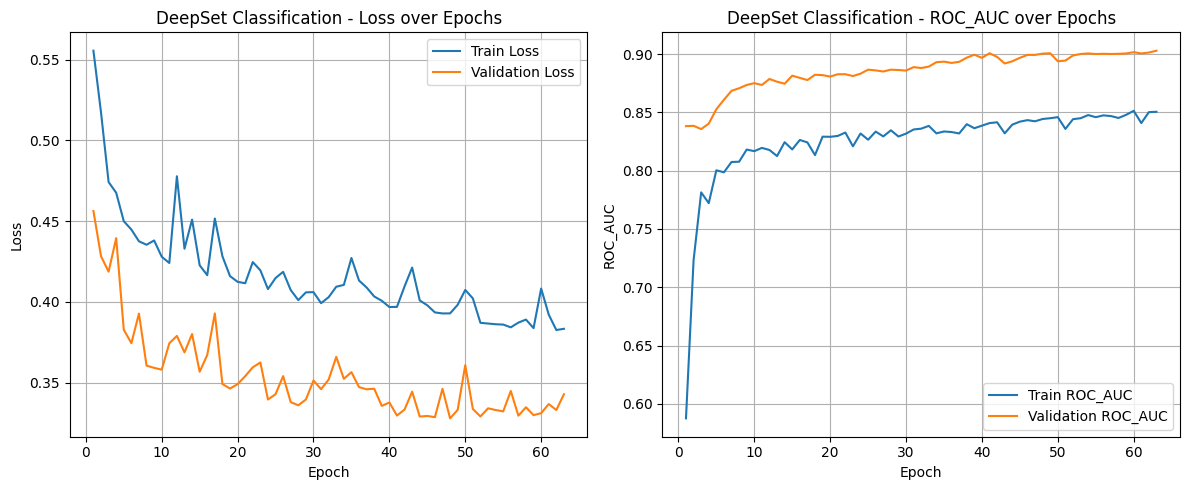


>>> FINAL AGGREGATED RESULTS FOR DeepSet Classification <<<
Total time taken: 62.52 seconds
  Test ROC_AUC: 0.6933 ± 0.0013


In [13]:
# Setup for BBBP (Classification)
# There are 9 features in the BBBP dataset
bbbp_max_vals = get_max_values(bbbp)
class_batch_size = 32
class_n_epochs = 200
class_onehot_sizes = bbbp_max_vals[1:]
in_features_classification = embedding_dim + sum([size + 1 for size in bbbp_max_vals[1:]])

if DEBUG_MODE:
    class_n_epochs = 1
    bbbp_train_dataset = torch.utils.data.Subset(bbbp_train_dataset, range(min(10, len(bbbp_train_dataset))))
    bbbp_val_dataset = torch.utils.data.Subset(bbbp_val_dataset, range(min(5, len(bbbp_val_dataset))))
    bbbp_test_dataset = torch.utils.data.Subset(bbbp_test_dataset, range(min(5, len(bbbp_test_dataset))))

# --- CLASSIFICATION EXPERIMENTS (BBBP) ---
cls_results = {}
cls_results["DeepSet"] = run_experiment(MolecularGraphClassification,
               {"embedding": torch.nn.Embedding(num_embeddings=bbbp_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": DeepSet(in_features_classification, hidden_features),
                "onehot_sizes": class_onehot_sizes,
                "name": "DeepSet Classification"},
               bbbp_train_dataset, bbbp_val_dataset, bbbp_test_dataset, class_batch_size, class_n_epochs)


Running Experiment: GCN Classification (3 replicates)

--- Replicate 1/3 ---
Training GCN Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(63, 64)
      (1): GCNConv(64, 64)
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 10,049

Epoch 5/200
  Train - Loss: 0.4898, roc_auc: 0.7914
  Val   - Loss: 0.3928, roc_auc: 0.8665
Epoch 10/200
  Train - Loss: 0.4182, roc_auc: 0.8215
  Val   - Loss: 0.3695, roc_auc: 0.8762
Epoch 15/200
  Train - Loss: 0.4228, roc_auc: 0.8190
  Val   - Loss: 0.3712, roc_auc: 0.8806
Epoch 20/200
  Train - Loss: 0.3885, roc_auc: 0.8503
  Val   - Loss: 0.3513, roc_auc: 0.8809
Epoch 25/200
  Train - Loss: 0.3907, roc_auc: 0.8431
  Val   - Loss: 0.3658, roc_

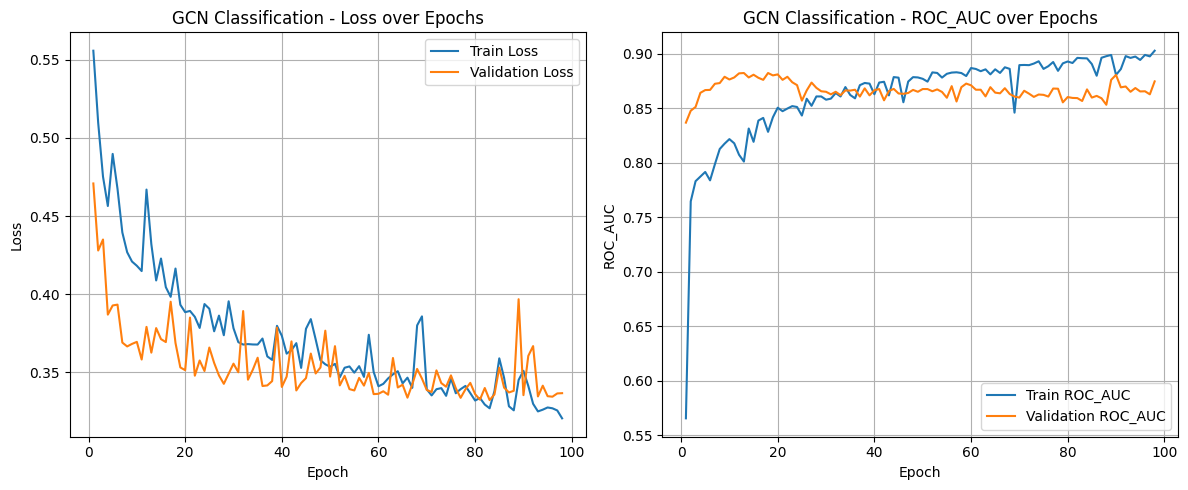


--- Replicate 2/3 ---
Training GCN Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(63, 64)
      (1): GCNConv(64, 64)
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 10,049

Epoch 5/200
  Train - Loss: 0.4890, roc_auc: 0.7838
  Val   - Loss: 0.4176, roc_auc: 0.8693
Epoch 10/200
  Train - Loss: 0.4295, roc_auc: 0.8142
  Val   - Loss: 0.3606, roc_auc: 0.8734
Epoch 15/200
  Train - Loss: 0.4243, roc_auc: 0.8121
  Val   - Loss: 0.3568, roc_auc: 0.8748
Epoch 20/200
  Train - Loss: 0.4084, roc_auc: 0.8313
  Val   - Loss: 0.3392, roc_auc: 0.8860
Epoch 25/200
  Train - Loss: 0.4194, roc_auc: 0.8417
  Val   - Loss: 0.3670, roc_auc: 0.8838
Epoch 30/200
  Train - Loss: 0.3799, roc_au

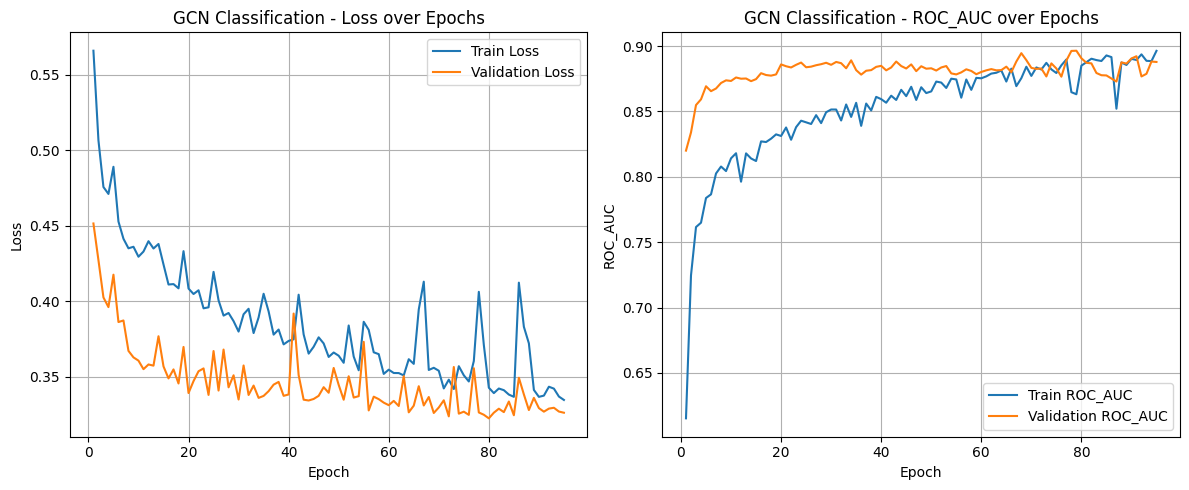


--- Replicate 3/3 ---
Training GCN Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GCN Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GCN(
    (layers): ModuleList(
      (0): GCNConv(63, 64)
      (1): GCNConv(64, 64)
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 10,049

Epoch 5/200
  Train - Loss: 0.4688, roc_auc: 0.7739
  Val   - Loss: 0.4156, roc_auc: 0.8576
Epoch 10/200
  Train - Loss: 0.4730, roc_auc: 0.8056
  Val   - Loss: 0.4714, roc_auc: 0.8629
Epoch 15/200
  Train - Loss: 0.4244, roc_auc: 0.8186
  Val   - Loss: 0.3511, roc_auc: 0.8741
Epoch 20/200
  Train - Loss: 0.4069, roc_auc: 0.8293
  Val   - Loss: 0.3614, roc_auc: 0.8718
Epoch 25/200
  Train - Loss: 0.4123, roc_auc: 0.8280
  Val   - Loss: 0.3671, roc_auc: 0.8795
Epoch 30/200
  Train - Loss: 0.3914, roc_au

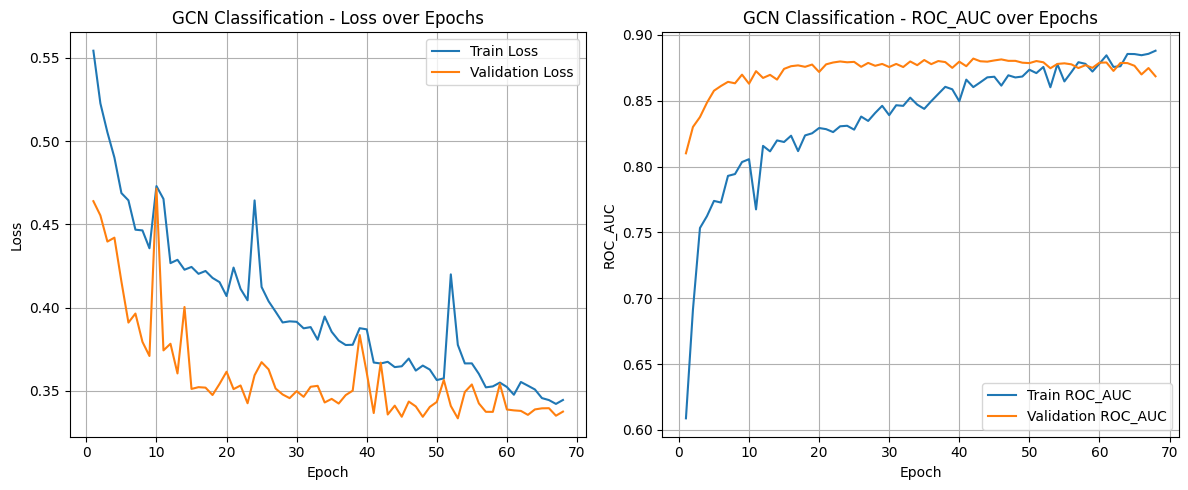


>>> FINAL AGGREGATED RESULTS FOR GCN Classification <<<
Total time taken: 128.40 seconds
  Test ROC_AUC: 0.7859 ± 0.0165


In [14]:
cls_results["GCN"] = run_experiment(MolecularGraphClassification,
               {"embedding": torch.nn.Embedding(num_embeddings=bbbp_max_vals[0]+1, embedding_dim=embedding_dim),
                "net": GCN(in_features_classification, hidden_features),
                "onehot_sizes": class_onehot_sizes,
                "name": "GCN Classification"},
               bbbp_train_dataset, bbbp_val_dataset, bbbp_test_dataset, class_batch_size, class_n_epochs)


Running Experiment: GAT Classification (3 replicates)

--- Replicate 1/3 ---
Training GAT Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(63, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(64, 64, heads=4)
      (3): ELU(alpha=1.0)
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 35,457

Epoch 5/200
  Train - Loss: 0.4325, roc_auc: 0.8038
  Val   - Loss: 0.3976, roc_auc: 0.8721
Epoch 10/200
  Train - Loss: 0.4077, roc_auc: 0.8173
  Val   - Loss: 0.3882, roc_auc: 0.8727
Epoch 15/200
  Train - Loss: 0.4203, roc_auc: 0.8039
  Val   - Loss: 0.3799, roc_auc: 0.8601
Epoch 20/200
  Train - Loss: 0.3935, roc_auc: 0.8406
  Val   - Loss: 0.3884, roc_auc: 0.8726
Epoch 25/20

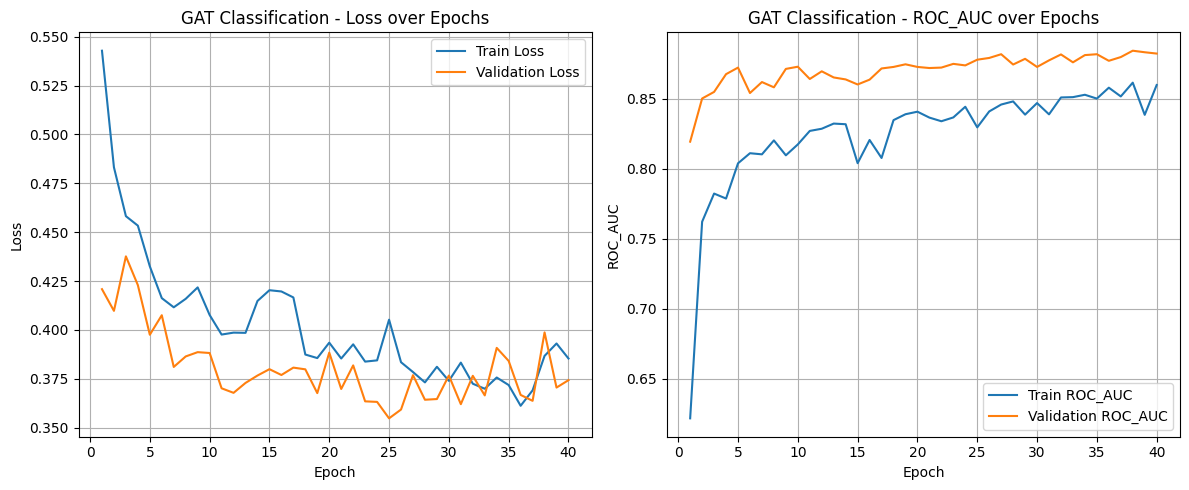


--- Replicate 2/3 ---
Training GAT Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(63, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(64, 64, heads=4)
      (3): ELU(alpha=1.0)
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 35,457

Epoch 5/200
  Train - Loss: 0.4407, roc_auc: 0.7925
  Val   - Loss: 0.3867, roc_auc: 0.8602
Epoch 10/200
  Train - Loss: 0.4196, roc_auc: 0.8199
  Val   - Loss: 0.3784, roc_auc: 0.8643
Epoch 15/200
  Train - Loss: 0.3950, roc_auc: 0.8288
  Val   - Loss: 0.3655, roc_auc: 0.8821
Epoch 20/200
  Train - Loss: 0.3835, roc_auc: 0.8464
  Val   - Loss: 0.3419, roc_auc: 0.8904
Epoch 25/200
  Train - Loss: 0.3898, roc_auc: 0.8495
  Val   - Los

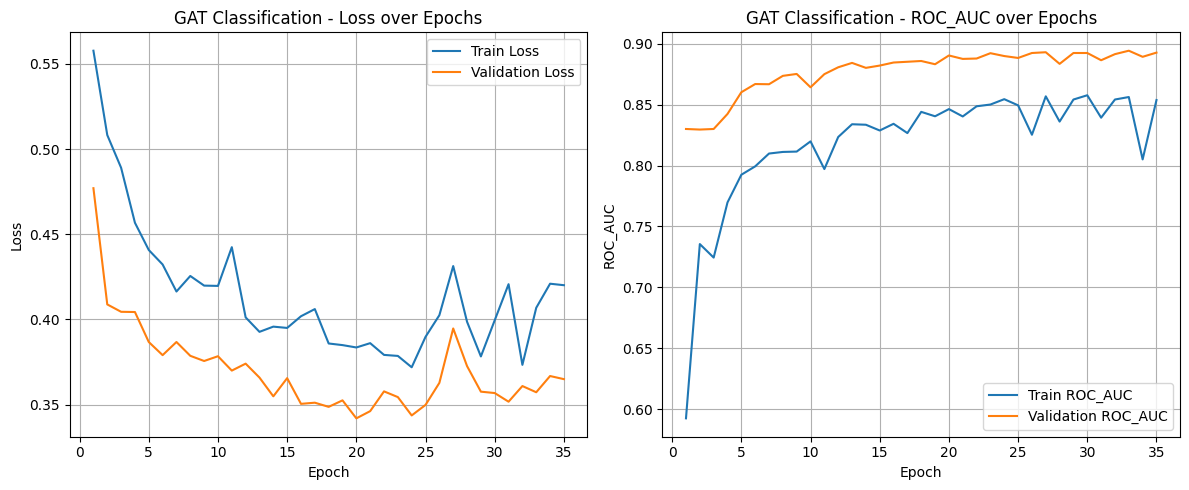


--- Replicate 3/3 ---
Training GAT Classification with 32 batch size for 200 epochs (Early Stopping Patience: 15)...

Architecture of GAT Classification after first forward pass:
MolecularGraphClassification(
  (embedding): Embedding(54, 32)
  (net): GAT(
    (layers): ModuleList(
      (0): GATConv(63, 64, heads=4)
      (1): ELU(alpha=1.0)
      (2): GATConv(64, 64, heads=4)
      (3): ELU(alpha=1.0)
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (sigmoid): Sigmoid()
  (bce_loss): BCELoss()
)
Total Trainable Parameters: 35,457

Epoch 5/200
  Train - Loss: 0.4528, roc_auc: 0.7783
  Val   - Loss: 0.4010, roc_auc: 0.8662
Epoch 10/200
  Train - Loss: 0.3952, roc_auc: 0.8314
  Val   - Loss: 0.3676, roc_auc: 0.8755
Epoch 15/200
  Train - Loss: 0.3843, roc_auc: 0.8432
  Val   - Loss: 0.3516, roc_auc: 0.8793
Epoch 20/200
  Train - Loss: 0.3760, roc_auc: 0.8510
  Val   - Loss: 0.3464, roc_auc: 0.8856
Epoch 25/200
  Train - Loss: 0.3680, roc_auc: 0.8590
  Val   - Los

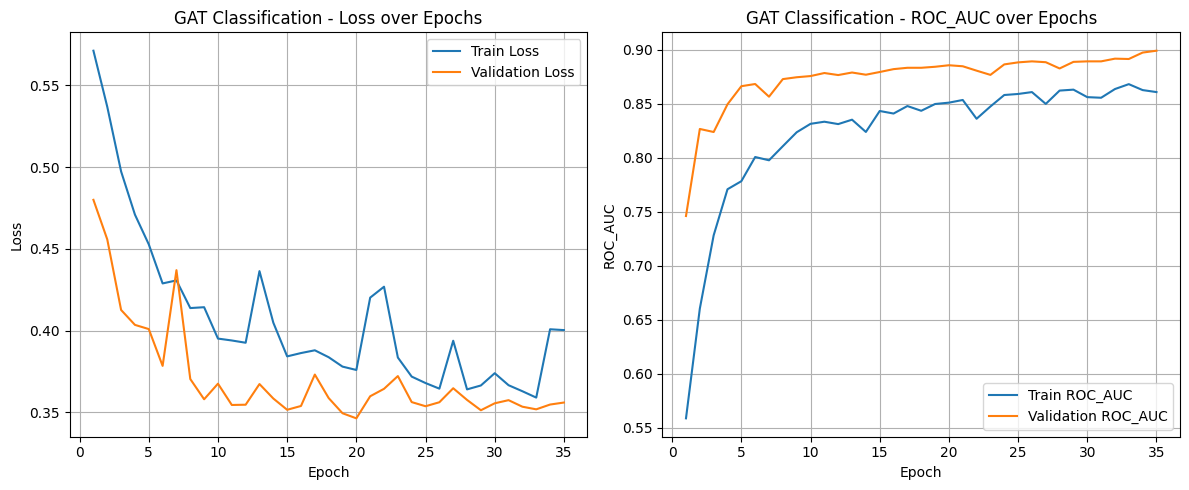


>>> FINAL AGGREGATED RESULTS FOR GAT Classification <<<
Total time taken: 136.76 seconds
  Test ROC_AUC: 0.7089 ± 0.0239


In [15]:
cls_results["GAT"] = run_experiment(MolecularGraphClassification,
               {"embedding": torch.nn.Embedding(num_embeddings=bbbp_max_vals[0]+1, embedding_dim=embedding_dim),

                "net": GAT(in_features_classification, hidden_features, heads=4),
                "onehot_sizes": class_onehot_sizes,
                "name": "GAT Classification"},
               bbbp_train_dataset, bbbp_val_dataset, bbbp_test_dataset, class_batch_size, class_n_epochs)


Generating comparison plots...

FINAL RESULTS FOR REGRESSION

Model: DeepSet
  Test RMSE: 1.3564 ± 0.0398
  Test PCC: 0.7761 ± 0.0177

Model: GCN
  Test RMSE: 1.5820 ± 0.0950
  Test PCC: 0.7270 ± 0.0584

Model: GAT
  Test RMSE: 1.4896 ± 0.0939
  Test PCC: 0.7153 ± 0.0434


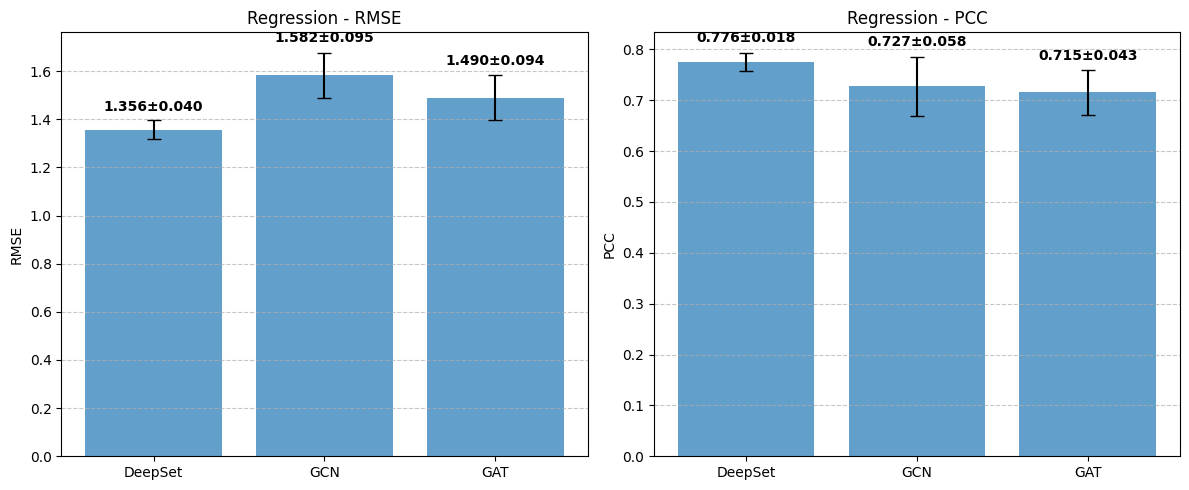


FINAL RESULTS FOR CLASSIFICATION

Model: DeepSet
  Test ROC_AUC: 0.6933 ± 0.0013

Model: GCN
  Test ROC_AUC: 0.7859 ± 0.0165

Model: GAT
  Test ROC_AUC: 0.7089 ± 0.0239


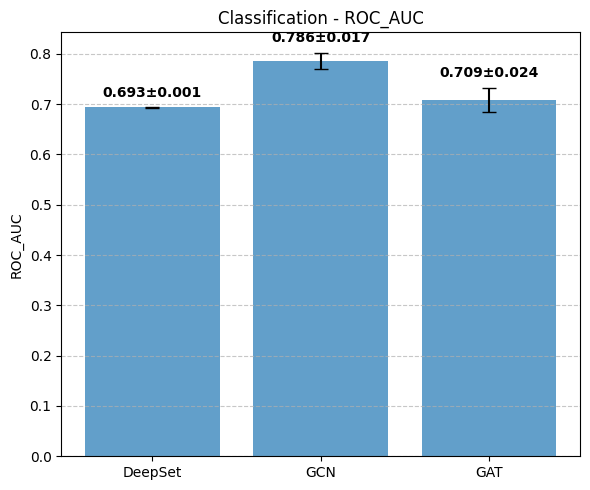

In [16]:

def plot_final_comparison(results_dict, task_name, metrics):
    print(f"\n{'='*50}\nFINAL RESULTS FOR {task_name.upper()}\n{'='*50}")
    for model_name, metrics_data in results_dict.items():
        print(f"\nModel: {model_name}")
        for metric in metrics:
            mean, std = metrics_data[metric]
            print(f"  Test {metric.upper()}: {mean:.4f} ± {std:.4f}")

    num_metrics = len(metrics)
    fig, axes = plt.subplots(1, num_metrics, figsize=(6 * num_metrics, 5))
    if num_metrics == 1:
        axes = [axes]

    models = list(results_dict.keys())

    for i, metric in enumerate(metrics):
        means = [results_dict[m][metric][0] for m in models]
        stds = [results_dict[m][metric][1] for m in models]

        bars = axes[i].bar(models, means, yerr=stds, capsize=5, alpha=0.7)
        axes[i].set_title(f'{task_name} - {metric.upper()}')
        axes[i].set_ylabel(metric.upper())
        axes[i].grid(axis='y', linestyle='--', alpha=0.7)

        # Add numeric labels on top of the bars for easy reading
        for bar, mean, std in zip(bars, means, stds):
            yval = bar.get_height()
            # Position the text slightly above the error bar
            axes[i].text(bar.get_x() + bar.get_width()/2, yval + std + (0.02 * abs(yval)),
                         f'{mean:.3f}±{std:.3f}',
                         ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.savefig(f"{task_name.lower()}_comparison.png")
    plt.show()

print("\nGenerating comparison plots...")
plot_final_comparison(reg_results, "Regression", ["rmse", "pcc"])
plot_final_comparison(cls_results, "Classification", ["roc_auc"])

Here's a brief outline of what has been done:

1.  **Installed necessary libraries:** Installed `torch`, `torch_geometric`, `rdkit`, `torcheval`, and `matplotlib`, and cloned a GitHub repository containing relevant code.
2.  **Set up the device:** Determined whether to use CUDA, MPS, or CPU for training.
3.  **Loaded and filtered datasets:** Loaded the ESOL and BBBP datasets using `torch_geometric.datasets.MoleculeNet`. A function `filter_small_graphs` was implemented and used to remove molecules with fewer than 2 nodes from both datasets.
4.  **Split datasets:** Split the filtered ESOL and BBBP datasets into training and validation sets using a scaffold split.
5. **Defined Model Architectures:** Created classes for base molecular graph networks (`MolecularGraphNet`), and specific implementations for classification (`MolecularGraphClassification`) and regression (`MolecularGraphRegression`). We also defined the architectures for different graph neural network layers: `DeepSet`, `GCN`, and `GAT`. As our baseline, we implemented a DeepSet architecture for both regression and classification that ignores graph structure. We tried different batch sizes to improve performance while also preventing issues during training (such as Pearson correlation not being defined). This model serves as an important baseline to determine whether graph structure provides meaningful signal beyond node features alone. For our spatial models, we implemented GCN based on Kipf & Welling [2], using the layer-wise propagation rule:
   
   $H^{(l+1)} = \sigma(\tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2} H^{(l)} W^{(l)})$

   where $\tilde{A} = A + I_N$ is the adjacency matrix with self-connections and $\tilde{D}$ is the corresponding degree matrix. This formulation provides an efficient first-order approximation of spectral graph convolutions.

6.  **Defined Training and Plotting Functions:** Implemented functions for plotting training results (`plot_results`) and training the models (`train`), including logging with Weights & Biases. A helper function `get_max_values` was created to determine feature dimensions for embedding.
7.  **Instantiated and Trained Models:** Initialized and trained instances of `MolecularGraphRegression` (using DeepSet, GCN, and GAT) on the ESOL dataset and `MolecularGraphClassification` (again using DeepSet, GCN and GAT) on the BBBP dataset.

## Model Comparison

Below is the comparison of the different models on the ESOL (Regression) and BBBP (Classification) tasks:

1. **DeepSet (Baseline)**: This model applies a per-node MLP and then pools the results globally. It does not use the graph structure (edges) at all. It serves as a baseline to see how much can be learned purely from atomic properties without structural context.
2. **GCN (Graph Convolutional Network)**: GCN aggregates features from immediate neighbors using an isotropic weighting scheme based on node degrees. It can capture local structural motifs but struggles to distinguish between neighbors of different importance.
3. **GAT (Graph Attention Network)**: GAT uses an attention mechanism to learn dynamic weights for different neighbors. To maintain a fair and equal parameter count against the GCN baseline, we constrained the model to a single attention head. It theoretically can attend to specific chemical bonds that are most relevant to the target property.

**Discussion**:
Initially, it was hypothesized that GCN and GAT would easily outperform the DeepSet baseline, as molecular properties generally depend heavily on the structural arrangement of atoms (e.g., rings, functional groups). However, our empirical results revealed a more nuanced reality depending on the specific physical domain of the dataset.

For the **ESOL regression task**, the DeepSet baseline surprisingly outperformed both graph networks. One can assume that because solubility is largely an additive property driven by the atoms within a molecule, identifying atomic features without topological context is highly effective. The graph models likely overcomplicated the problem by attempting to map complex pathways, resulting in slight overfitting and degraded performance.

Conversely, for the **BBBP classification task**, GCN significantly outperformed DeepSet. One can assume that passing through the blood-brain barrier is a highly selective biological process that demands a specific structural shape and geometry. Merely knowing the atomic composition is not enough and the model must understand the molecular graph connectivity, which allowed the GCN to excel.

Finally, when comparing the two graph architectures, GCN outperformed GAT. While GAT's attention mechanism is theoretically more expressive, one can assume that attention networks are highly data-hungry. Because the subsets of the MoleculeNet datasets used here are relatively tiny, the GAT struggled to learn meaningful, dynamic attention weights. In contrast, the GCN's fixed, mathematically normalized averaging rule proved to be a much more robust and reliable inductive bias for small datasets.


### Analysis of Training vs. Validation Metrics

Throughout the training logs for both tasks, an interesting paradox emerges: the validation metrics (PCC and ROC-AUC) consistently outperform the training metrics, even when the validation loss (MSE/BCE) is strictly worse than the training loss. We assume this phenomenon is driven by two primary factors:

First, the discrepancy highlights the fundamental mathematical difference between absolute error and correlation. For example, in the ESOL regression task, a model might predict values with a massive, consistent offset on the validation set, resulting in a terrible Mean Squared Error (Loss). However, because those predictions still move perfectly in sync with the true values, the Pearson Correlation Coefficient (PCC) remains exceptionally high.

Second, the dataset was partitioned using a `ScaffoldSplitter`, meaning the validation set is not a random sample, but rather consists of distinct chemical families. If the validation set was assigned a chemical scaffold that is structurally simpler or has a more straightforward, linear relationship with the target property, the model will naturally achieve a higher correlation or ROC-AUC score on those "easy" molecules compared to the highly complex, diverse training set. Furthermore, because training metrics are calculated as a running average over the epoch while the model is still learning, the validation metrics, calculated at the very end of the epoch with fully updated weights, naturally receive a slight advantage.
